## ✈ Airline Route Profitability Analyzer ✈

In this project, we are going to estimate which routes are financially attractive by comparing estimated revenue with operating costs.

### 1. Generate Synthetic Route Data
We will define a set of key flight routes with details including flight distance, passenger capacity, base ticket prices, weekly flight frequencies, and aircraft fuel burn rates.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual style
sns.set_theme(style="whitegrid")

# 1. Generate Synthetic Route Data
routes_data = {
    'Route': ['JFK-LAX', 'ORD-LHR', 'MIA-DFW', 'SFO-HND', 'ATL-MCO', 'SEA-ANC'],
    'Distance_Miles': [2475, 3950, 1120, 5130, 400, 1450],
    'Capacity': [180, 250, 150, 300, 150, 120],          # Seats per aircraft
    'Average_Ticket_Price': [350, 750, 180, 950, 90, 220], # Base fare in USD
    'Weekly_Flights': [14, 7, 21, 5, 28, 10],
    'Fuel_Burn_GPM': [1.5, 2.2, 1.2, 2.8, 1.1, 1.0]       # Fuel burn rate (gallons per mile)
}

routes_df = pd.DataFrame(routes_data)
display(routes_df)

,Route,Distance_Miles,Capacity,Average_Ticket_Price,Weekly_Flights,Fuel_Burn_GPM
0,JFK-LAX,2475,180,350,14,1.5
1,ORD-LHR,3950,250,750,7,2.2
2,MIA-DFW,1120,150,180,21,1.2
3,SFO-HND,5130,300,950,5,2.8
4,ATL-MCO,400,150,90,28,1.1
5,SEA-ANC,1450,120,220,10,1.0


### 2. Revenue, Cost, and Profitability Calculations
Next, we will construct a function to calculate revenues and operating costs for each route.
- Operating Cost includes fuel cost, crew hourly costs, and airport landing fees based on capacity.
- Estimated Revenue relies on seat capacity, ticket prices, and the target Passenger Load Factor (LF).

In [ ]:
def calculate_profitability(df, fuel_price_per_gal=3.00, load_factor=0.80, crew_hourly_rate=500.0, avg_speed_mph=500.0):
    """
    Computes revenue, operational costs, and profits based on customizable financial drivers.
    """
    results = df.copy()

    # Flight metrics
    results['Flight_Duration_Hours'] = results['Distance_Miles'] / avg_speed_mph
    results['Passengers'] = (results['Capacity'] * load_factor).astype(int)

    # Revenue generation per flight
    results['Flight_Revenue'] = results['Passengers'] * results['Average_Ticket_Price']

    # Cost calculations per flight
    results['Fuel_Cost'] = results['Distance_Miles'] * results['Fuel_Burn_GPM'] * fuel_price_per_gal
    results['Crew_Cost'] = results['Flight_Duration_Hours'] * crew_hourly_rate
    results['Landing_Fee'] = results['Capacity'] * 5.0  # Assumed fee parameter per seat capacity
    results['Total_Flight_Cost'] = results['Fuel_Cost'] + results['Crew_Cost'] + results['Landing_Fee']

    # Weekly aggregations
    results['Weekly_Revenue'] = results['Flight_Revenue'] * results['Weekly_Flights']
    results['Weekly_Cost'] = results['Total_Flight_Cost'] * results['Weekly_Flights']
    results['Weekly_Profit'] = results['Weekly_Revenue'] - results['Weekly_Cost']
    results['Profit_Margin_%'] = (results['Weekly_Profit'] / results['Weekly_Revenue']) * 100

    return results

# Calculate Baseline Profitability
baseline_results = calculate_profitability(routes_df)
display(baseline_results[['Route', 'Weekly_Revenue', 'Weekly_Cost', 'Weekly_Profit', 'Profit_Margin_%']].sort_values(by='Weekly_Profit', ascending=False))

,Route,Weekly_Revenue,Weekly_Cost,Weekly_Profit,Profit_Margin_%
3,SFO-HND,1140000,248610.0,891390.0,78.192105
1,ORD-LHR,1050000,218890.0,831110.0,79.153333
0,JFK-LAX,705600,203175.0,502425.0,71.205357
2,MIA-DFW,453600,123942.0,329658.0,72.675926
4,ATL-MCO,302400,69160.0,233240.0,77.129630
5,SEA-ANC,211200,64000.0,147200.0,69.696970


### 3. Scenario Comparison and Interactive Dashboard
Next, let's evaluate how different scenarios affect weekly route profitability and rank them dynamically.

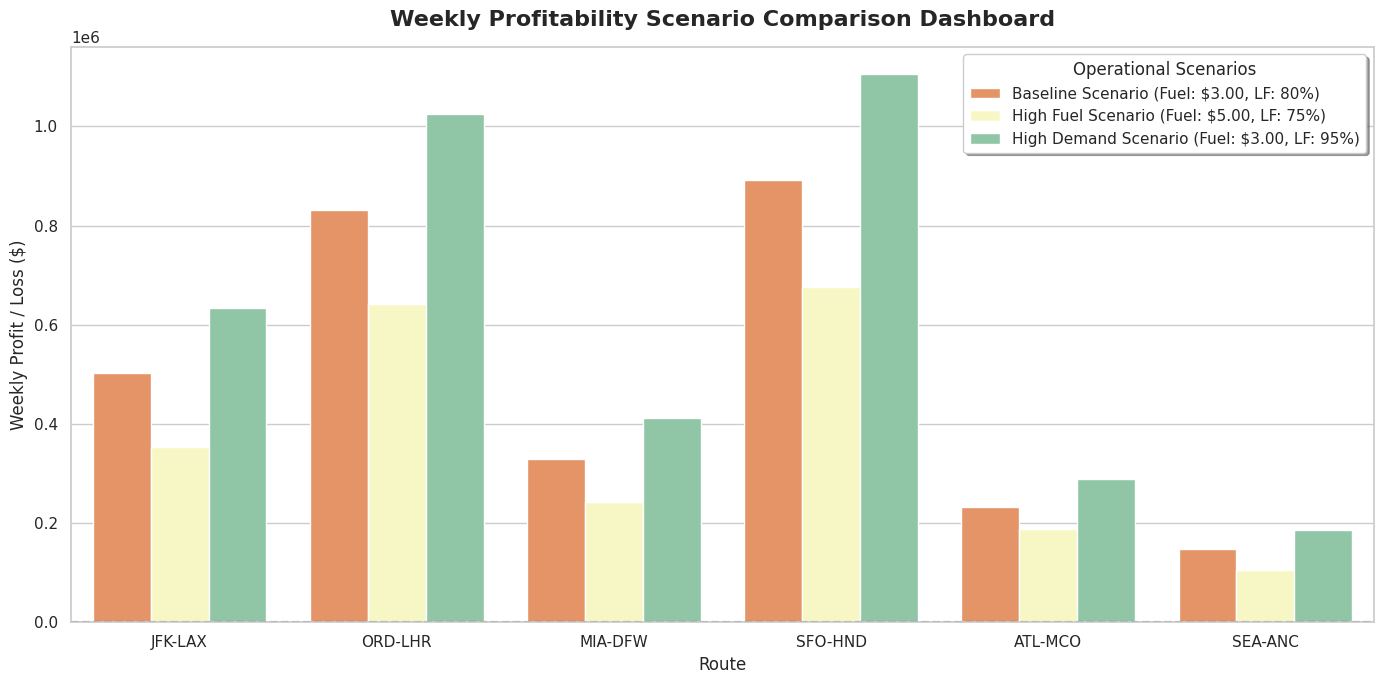

In [ ]:
# 1. Evaluate scenarios
scenario_baseline = calculate_profitability(routes_df, fuel_price_per_gal=3.00, load_factor=0.80)
scenario_high_fuel = calculate_profitability(routes_df, fuel_price_per_gal=5.00, load_factor=0.75)
scenario_high_occupancy = calculate_profitability(routes_df, fuel_price_per_gal=3.00, load_factor=0.95)

# 2. Combine results
comparison_df = pd.DataFrame({
    'Route': routes_df['Route'],
    'Baseline Scenario (Fuel: $3.00, LF: 80%)': scenario_baseline['Weekly_Profit'],
    'High Fuel Scenario (Fuel: $5.00, LF: 75%)': scenario_high_fuel['Weekly_Profit'],
    'High Demand Scenario (Fuel: $3.00, LF: 95%)': scenario_high_occupancy['Weekly_Profit']
})

# Melt dataframe for structured plotting
comparison_melted = pd.melt(comparison_df, id_vars=['Route'], var_name='Scenario', value_name='Weekly_Profit')

# 3. Create the Dashboard Visualisation
plt.figure(figsize=(14, 7))
sns.barplot(data=comparison_melted, x='Route', y='Weekly_Profit', hue='Scenario', palette='Spectral')
plt.title('Weekly Profitability Scenario Comparison Dashboard', fontsize=16, fontweight='bold', pad=15)
plt.ylabel('Weekly Profit / Loss ($)', fontsize=12)
plt.xlabel('Route', fontsize=12)
plt.axhline(0, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
plt.legend(title='Operational Scenarios', frameon=True, shadow=True)
plt.tight_layout()
plt.show()

### 4. Carbon Tax Impact Analysis
To make our Route Profitability Analyzer more comprehensive, let's incorporate environmental costs. We will define a carbon tax per metric ton of CO2 emissions.
- Aviation jet fuel produces approximately 9.57 kg of CO2 per gallon of fuel burned.
- We can define a parameter `carbon_tax_per_ton` (e.g., $50/metric ton) to assess how this regulatory cost affects our route profitability margins.

In [ ]:
def calculate_profitability_with_carbon_tax(df, fuel_price_per_gal=3.00, load_factor=0.80, crew_hourly_rate=500.0, avg_speed_mph=500.0, carbon_tax_per_ton=50.0):
    """
    Computes route revenue and operating costs including a CO2 carbon tax penalty.
    """
    results = df.copy()

    # Basic flight metrics
    results['Flight_Duration_Hours'] = results['Distance_Miles'] / avg_speed_mph
    results['Passengers'] = (results['Capacity'] * load_factor).astype(int)

    # Revenue
    results['Flight_Revenue'] = results['Passengers'] * results['Average_Ticket_Price']

    # Fuel & Carbon Calculations
    results['Fuel_Gallons'] = results['Distance_Miles'] * results['Fuel_Burn_GPM']
    # 1 gallon of jet fuel ≈ 9.57 kg CO2. Convert kg to metric tons (1 metric ton = 1000 kg)
    results['CO2_Metric_Tons'] = (results['Fuel_Gallons'] * 9.57) / 1000.0
    results['Carbon_Tax_Cost'] = results['CO2_Metric_Tons'] * carbon_tax_per_ton

    # Operational Costs
    results['Fuel_Cost'] = results['Fuel_Gallons'] * fuel_price_per_gal
    results['Crew_Cost'] = results['Flight_Duration_Hours'] * crew_hourly_rate
    results['Landing_Fee'] = results['Capacity'] * 5.0

    # Total Cost with Carbon Tax
    results['Total_Flight_Cost_No_Tax'] = results['Fuel_Cost'] + results['Crew_Cost'] + results['Landing_Fee']
    results['Total_Flight_Cost_With_Tax'] = results['Total_Flight_Cost_No_Tax'] + results['Carbon_Tax_Cost']

    # Weekly aggregations
    results['Weekly_Revenue'] = results['Flight_Revenue'] * results['Weekly_Flights']
    results['Weekly_Cost_With_Tax'] = results['Total_Flight_Cost_With_Tax'] * results['Weekly_Flights']
    results['Weekly_Profit_With_Tax'] = results['Weekly_Revenue'] - results['Weekly_Cost_With_Tax']
    results['Weekly_Carbon_Tax'] = results['Carbon_Tax_Cost'] * results['Weekly_Flights']

    return results

# Run the carbon tax analysis (e.g., baseline conditions vs $50/ton vs $150/ton carbon tax)
tax_free_df = calculate_profitability_with_carbon_tax(routes_df, carbon_tax_per_ton=0.0)
tax_moderate_df = calculate_profitability_with_carbon_tax(routes_df, carbon_tax_per_ton=50.0)
tax_aggressive_df = calculate_profitability_with_carbon_tax(routes_df, carbon_tax_per_ton=150.0)

# Combine and display a summary dataframe
carbon_comparison = pd.DataFrame({
    'Route': routes_df['Route'],
    'Weekly Profit (No Tax) ($)': tax_free_df['Weekly_Profit_With_Tax'],
    'Weekly Profit ($50/Ton) ($)': tax_moderate_df['Weekly_Profit_With_Tax'],
    'Weekly Profit ($150/Ton) ($)': tax_aggressive_df['Weekly_Profit_With_Tax'],
    'Weekly Carbon Tax Burden ($50/Ton) ($)': tax_moderate_df['Weekly_Carbon_Tax']
})
display(carbon_comparison.round(2))

,Route,Weekly Profit (No Tax) ($),Weekly Profit ($50/Ton) ($),Weekly Profit ($150/Ton) ($),Weekly Carbon Tax Burden ($50/Ton) ($)
0,JFK-LAX,502425.0,477554.96,427814.89,24870.04
1,ORD-LHR,831110.0,802002.84,743788.53,29107.16
2,MIA-DFW,329658.0,316152.82,289142.45,13505.18
3,SFO-HND,891390.0,857024.13,788292.39,34365.87
4,ATL-MCO,233240.0,227344.88,215554.64,5895.12
5,SEA-ANC,147200.0,140261.75,126385.25,6938.25


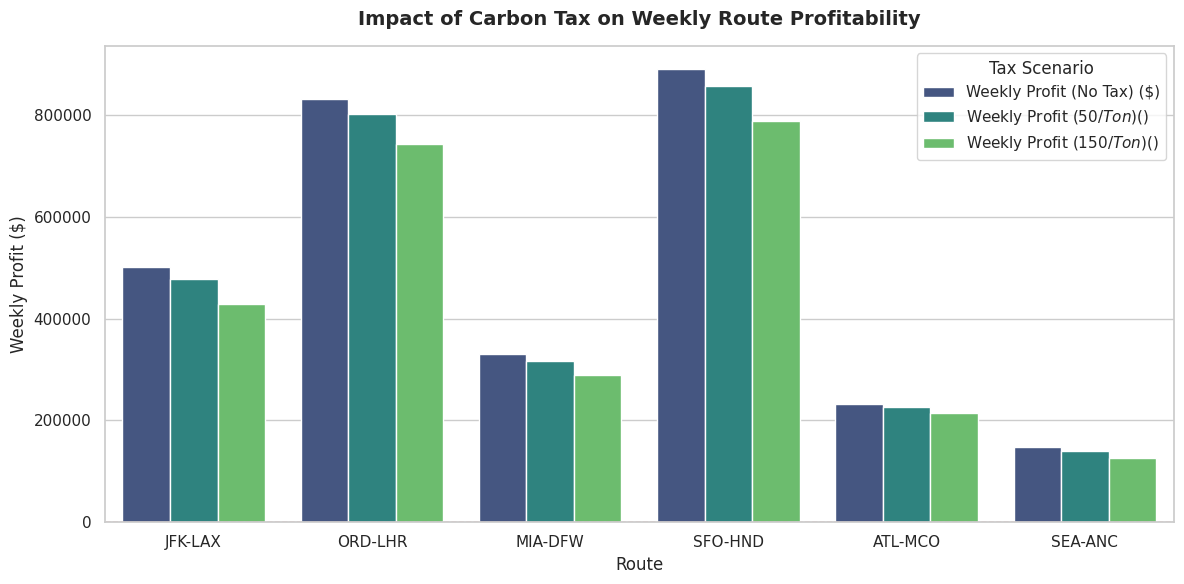

In [ ]:
# Reshape carbon comparison data for plotting
plot_data = pd.melt(
    carbon_comparison,
    id_vars=['Route'],
    value_vars=['Weekly Profit (No Tax) ($)', 'Weekly Profit ($50/Ton) ($)', 'Weekly Profit ($150/Ton) ($)'],
    var_name='Tax Scenario',
    value_name='Weekly Profit ($)'
)

# Create the bar chart
plt.figure(figsize=(12, 6))
sns.barplot(data=plot_data, x='Route', y='Weekly Profit ($)', hue='Tax Scenario', palette='viridis')

plt.title('Impact of Carbon Tax on Weekly Route Profitability', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Route', fontsize=12)
plt.ylabel('Weekly Profit ($)', fontsize=12)
plt.axhline(0, color='red', linestyle='--', linewidth=1, alpha=0.7)
plt.legend(title='Tax Scenario', frameon=True)
plt.tight_layout()
plt.show()

### 5. Return on Investment (ROI) per Carbon Tax Tier
To understand cost efficiency, we will calculate the Return on Investment (ROI) for each route.
$$\text{ROI (\%)} = \left( \frac{\text{Weekly Profit}}{\text{Weekly Cost}} \right) \times 100$$
We will compare the ROI under three regulatory scenarios:
1. No Carbon Tax ($0/Ton)

2. Moderate Carbon Tax ($50/Ton)

3. Aggressive Carbon Tax ($150/Ton)

In [ ]:
# Calculate ROI for each scenario
roi_comparison = pd.DataFrame({
    'Route': routes_df['Route'],
    'ROI (No Tax) (%)': (tax_free_df['Weekly_Profit_With_Tax'] / tax_free_df['Weekly_Cost_With_Tax']) * 100,
    'ROI ($50/Ton) (%)': (tax_moderate_df['Weekly_Profit_With_Tax'] / tax_moderate_df['Weekly_Cost_With_Tax']) * 100,
    'ROI ($150/Ton) (%)': (tax_aggressive_df['Weekly_Profit_With_Tax'] / tax_aggressive_df['Weekly_Cost_With_Tax']) * 100
})

display(roi_comparison.round(2))

,Route,ROI (No Tax) (%),ROI ($50/Ton) (%),ROI ($150/Ton) (%)
0,JFK-LAX,247.29,209.41,154.01
1,ORD-LHR,379.69,323.39,242.90
2,MIA-DFW,265.98,230.02,175.82
3,SFO-HND,358.55,302.86,224.13
4,ATL-MCO,337.25,302.90,248.21
5,SEA-ANC,230.00,197.72,149.01


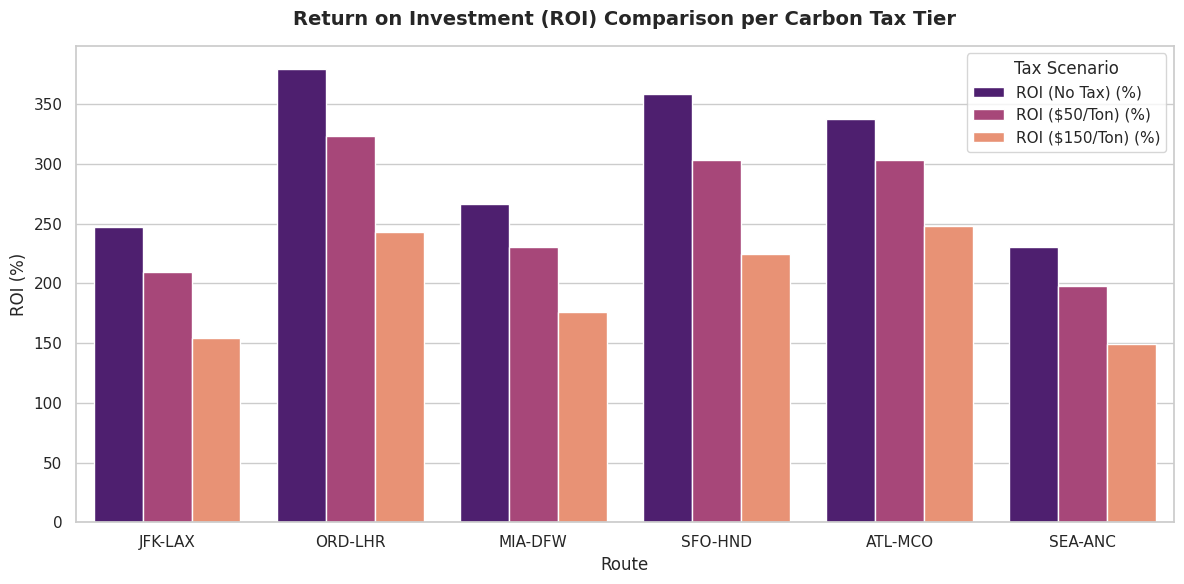

In [ ]:
# Melt the ROI dataframe for grouped bar plotting
roi_melted = pd.melt(
    roi_comparison,
    id_vars=['Route'],
    value_vars=['ROI (No Tax) (%)', 'ROI ($50/Ton) (%)', 'ROI ($150/Ton) (%)'],
    var_name='Tax Scenario',
    value_name='ROI (%)'
)

# Create the grouped bar chart for ROI
plt.figure(figsize=(12, 6))
sns.barplot(data=roi_melted, x='Route', y='ROI (%)', hue='Tax Scenario', palette='magma')

plt.title('Return on Investment (ROI) Comparison per Carbon Tax Tier', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Route', fontsize=12)
plt.ylabel('ROI (%)', fontsize=12)
plt.legend(title='Tax Scenario', frameon=True)
plt.tight_layout()
plt.show()

### 6. Identifying the Most Carbon-Efficient Route
To quantify carbon efficiency from an investment perspective, we analyze **ROI Retention**:
$$\text{ROI Retention (\%)} = \left( \frac{\text{ROI at \$150/Ton}}{\text{ROI at \$0/Ton}} \right) \times 100$$
A higher retention percentage means the route's financial performance is less vulnerable to carbon tax penalties, indicating superior fuel and emissions efficiency relative to its cost-to-revenue structure.

In [ ]:
# Calculate ROI retention percentage under the aggressive tax tier ($150/Ton)
roi_comparison['ROI_Retention_%'] = (roi_comparison['ROI ($150/Ton) (%)'] / roi_comparison['ROI (No Tax) (%)']) * 100

# Sort the routes to identify the most carbon-efficient route
carbon_efficiency_df = roi_comparison[['Route', 'ROI (No Tax) (%)', 'ROI ($150/Ton) (%)', 'ROI_Retention_%']].sort_values(by='ROI_Retention_%', ascending=False)

display(carbon_efficiency_df.round(2))

,Route,ROI (No Tax) (%),ROI ($150/Ton) (%),ROI_Retention_%
4,ATL-MCO,337.25,248.21,73.60
2,MIA-DFW,265.98,175.82,66.10
5,SEA-ANC,230.00,149.01,64.79
1,ORD-LHR,379.69,242.90,63.97
3,SFO-HND,358.55,224.13,62.51
0,JFK-LAX,247.29,154.01,62.28


### 7. Visualizing ROI Retention vs. Distance
To confirm the relationship between flight distance and carbon taxation resilience, we can map **ROI Retention (%)** directly against **Distance_Miles** using a scatter plot.

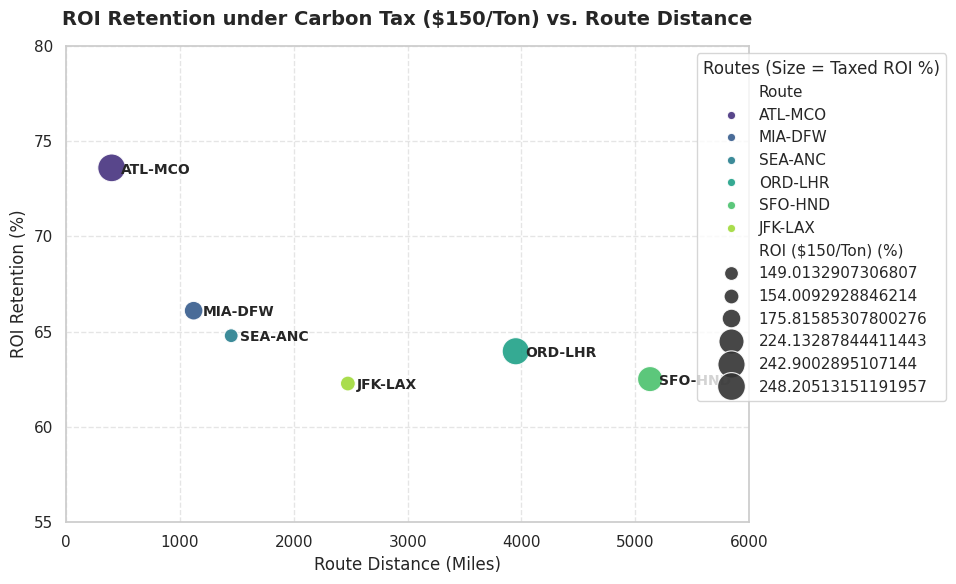

In [ ]:
# Merge distance details into our efficiency dataframe
plot_retention_df = carbon_efficiency_df.merge(routes_df[['Route', 'Distance_Miles']], on='Route')

# Create the scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=plot_retention_df,
    x='Distance_Miles',
    y='ROI_Retention_%',
    size='ROI ($150/Ton) (%)',
    hue='Route',
    palette='viridis',
    sizes=(100, 400),
    alpha=0.9
)

# Add annotations for each point
for i in range(len(plot_retention_df)):
    plt.text(
        x=plot_retention_df['Distance_Miles'].iloc[i] + 80,
        y=plot_retention_df['ROI_Retention_%'].iloc[i] - 0.3,
        s=plot_retention_df['Route'].iloc[i],
        fontweight='semibold',
        fontsize=10
    )

plt.title('ROI Retention under Carbon Tax ($150/Ton) vs. Route Distance', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Route Distance (Miles)', fontsize=12)
plt.ylabel('ROI Retention (%)', fontsize=12)
plt.ylim(55, 80)
plt.xlim(0, 6000)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Routes (Size = Taxed ROI %)', loc='upper right', bbox_to_anchor=(1.3, 1))
plt.tight_layout()
plt.show()

### 8. Linear Regression of ROI Retention vs. Distance
To mathematically quantify the relationship, we will perform a simple linear regression using `scipy.stats.linregress`. This will yield the correlation coefficient ($R$), the coefficient of determination ($R^2$), and the slope describing the exact loss of ROI retention per flight mile.

In [ ]:
from scipy import stats

# Extract variables
x = plot_retention_df['Distance_Miles']
y = plot_retention_df['ROI_Retention_%']

# Perform linear regression
slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)

print(f"Linear Regression Results:")
print(f"-------------------------")
print(f"Slope (ROI Retention % change per mile): {slope:.6f}")
print(f"Intercept (Theoretical 0-mile Retention): {intercept:.2f}%")
print(f"R-squared (Coefficient of Determination): {r_value**2:.4f}")
print(f"P-value: {p_value:.4f}")

Linear Regression Results:
-------------------------
Slope (ROI Retention % change per mile): -0.001650
Intercept (Theoretical 0-mile Retention): 69.54%
R-squared (Coefficient of Determination): 0.5071
P-value: 0.1124


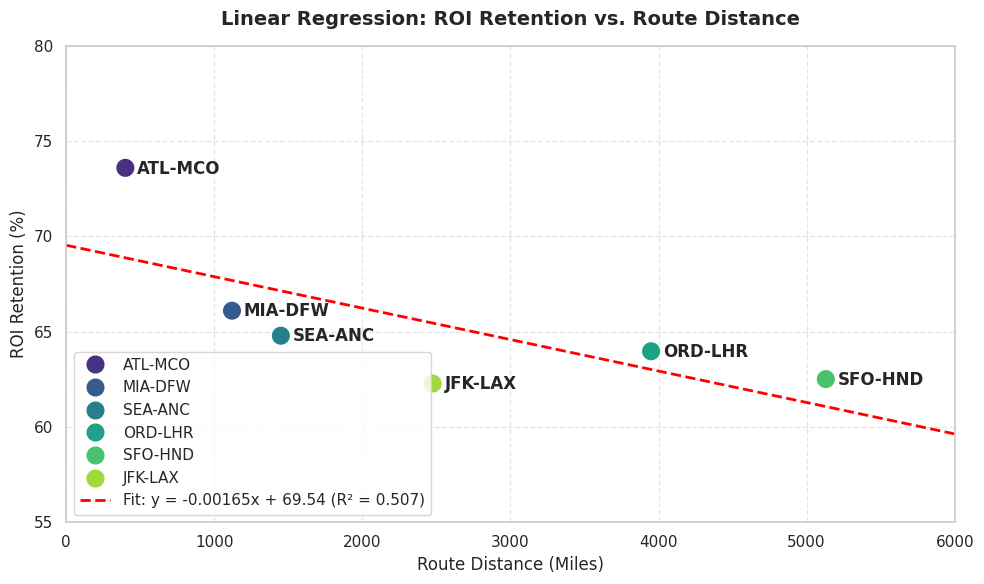

In [ ]:
# Plot the regression line on top of the scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=plot_retention_df,
    x='Distance_Miles',
    y='ROI_Retention_%',
    hue='Route',
    palette='viridis',
    s=200,
    legend=True
)

# Calculate regression line values
x_range = np.linspace(0, 6000, 100)
y_line = slope * x_range + intercept

plt.plot(x_range, y_line, color='red', linestyle='--', linewidth=2, label=f'Fit: y = {slope:.5f}x + {intercept:.2f} (R² = {r_value**2:.3f})')

# Annotations
for i in range(len(plot_retention_df)):
    plt.text(
        x=plot_retention_df['Distance_Miles'].iloc[i] + 80,
        y=plot_retention_df['ROI_Retention_%'].iloc[i] - 0.3,
        s=plot_retention_df['Route'].iloc[i],
        fontweight='semibold'
    )

plt.title('Linear Regression: ROI Retention vs. Route Distance', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Route Distance (Miles)', fontsize=12)
plt.ylabel('ROI Retention (%)', fontsize=12)
plt.ylim(55, 80)
plt.xlim(0, 6000)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

### 9. Comprehensive Route Performance Dashboard
This dashboard brings together the key financial, environmental, and resilience metrics we've computed to provide a single, actionable overview of all flight routes.

/tmp/ipykernel_2108/4101427389.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dashboard_df, x='Route', y='Baseline_Weekly_Profit', ax=axes[0, 0], palette='viridis')
/tmp/ipykernel_2108/4101427389.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dashboard_df, x='Route', y='Profit_Margin_%', ax=axes[0, 1], palette='plasma')
/tmp/ipykernel_2108/4101427389.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dashboard_df, x='Route', y='ROI_Retention_%', ax=axes[1, 0], palette='magma')


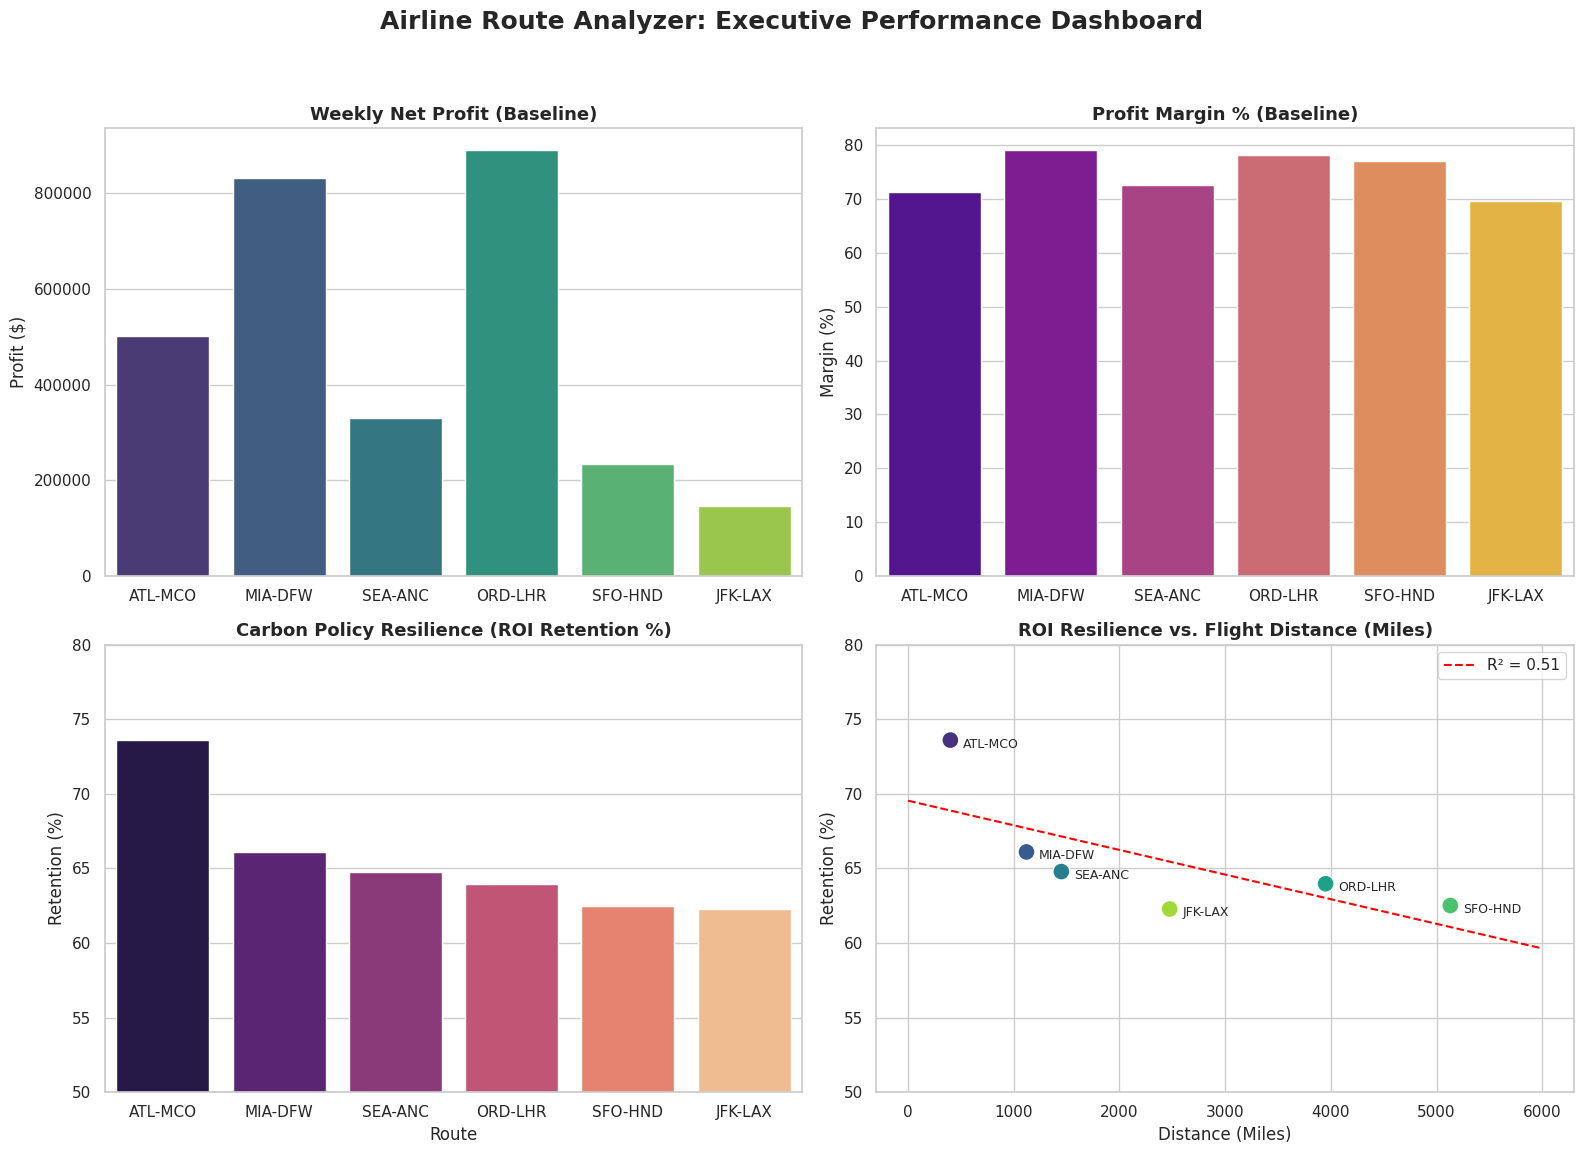

In [ ]:
# Prepare data for dashboard visualization
dashboard_df = plot_retention_df.copy()
dashboard_df['Baseline_Weekly_Profit'] = baseline_results['Weekly_Profit']
dashboard_df['Profit_Margin_%'] = baseline_results['Profit_Margin_%']

# Initialize subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Airline Route Analyzer: Executive Performance Dashboard', fontsize=18, fontweight='bold', y=0.96)

# 1. Weekly Profit (Baseline)
sns.barplot(data=dashboard_df, x='Route', y='Baseline_Weekly_Profit', ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Weekly Net Profit (Baseline)', fontsize=13, fontweight='semibold')
axes[0, 0].set_ylabel('Profit ($)')
axes[0, 0].set_xlabel('')

# 2. Baseline Profit Margin (%)
sns.barplot(data=dashboard_df, x='Route', y='Profit_Margin_%', ax=axes[0, 1], palette='plasma')
axes[0, 1].set_title('Profit Margin % (Baseline)', fontsize=13, fontweight='semibold')
axes[0, 1].set_ylabel('Margin (%)')
axes[0, 1].set_xlabel('')

# 3. ROI Retention vs Carbon Tax resilience
sns.barplot(data=dashboard_df, x='Route', y='ROI_Retention_%', ax=axes[1, 0], palette='magma')
axes[1, 0].set_title('Carbon Policy Resilience (ROI Retention %)', fontsize=13, fontweight='semibold')
axes[1, 0].set_ylabel('Retention (%)')
axes[1, 0].set_ylim(50, 80)

# 4. Correlation: ROI Retention vs Distance with Fit Line
sns.scatterplot(data=dashboard_df, x='Distance_Miles', y='ROI_Retention_%', hue='Route', s=150, ax=axes[1, 1], palette='viridis', legend=False)
line_x = np.linspace(0, 6000, 100)
line_y = slope * line_x + intercept
axes[1, 1].plot(line_x, line_y, color='red', linestyle='--', label=f'R² = {r_value**2:.2f}')
axes[1, 1].set_title('ROI Resilience vs. Flight Distance (Miles)', fontsize=13, fontweight='semibold')
axes[1, 1].set_xlabel('Distance (Miles)')
axes[1, 1].set_ylabel('Retention (%)')
axes[1, 1].set_ylim(50, 80)
axes[1, 1].legend()

# Annotation for scatter points in sub-plot 4
for i in range(len(dashboard_df)):
    axes[1, 1].text(
        x=dashboard_df['Distance_Miles'].iloc[i] + 120,
        y=dashboard_df['ROI_Retention_%'].iloc[i] - 0.5,
        s=dashboard_df['Route'].iloc[i],
        fontsize=9
    )

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()